# Tutorial Generative Adversarial Networks (GAN)

In this tutorial you will use a generative adversarial network to create images of handwritten digits.

It is recommended that you run this Notebook in Google Colab:
https://colab.research.google.com/.

## Before you start:

Change your Runtime settings to use a GPU, otherwise the waiting times will dramatically increase.

Go to:

Runtime > **Change Runtime **

Select: **T4 GPU**

This tutorial is an adaptation of the following Tensorflow tutorial:
https://www.tensorflow.org/tutorials/generative/dcgan

## 1) Import required libraries

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras import layers
import time

from IPython import display

## 2) Load the MNIST dataset

The MNIST dataset contains images of handwritten numbers (from 0 to 9).

You can explore the dataset here:
https://www.tensorflow.org/datasets/catalog/mnist
and here:
https://knowyourdata-tfds.withgoogle.com/#tab=STATS&dataset=mnist

We do not need a test set, as the model will generate new images of numbers, therefore we cannot compare them with other images of numbers because they will always look different.

In [2]:
(train_images, train_labels), (_, _) = tf.keras.datasets.mnist.load_data()

class_names = ["0", "1", "2", "3", "4", "5", "6", "7", "8", "9"]

## 3) Visualise some images from the dataset

The following coe displays the first 25 images of the dataset.

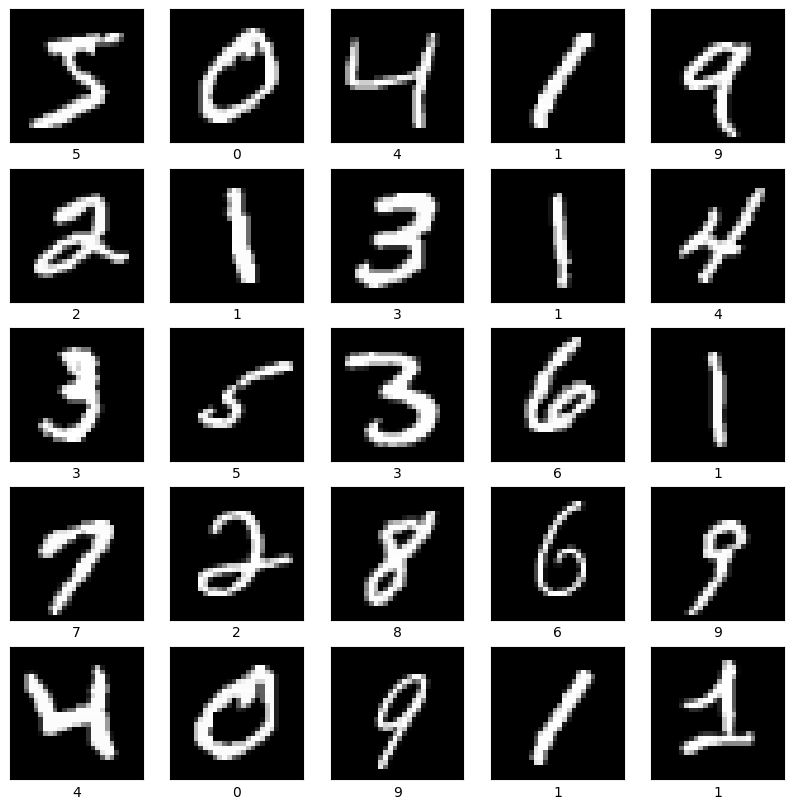

In [3]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
    # The CIFAR labels happen to be arrays,
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i]])
plt.show()

## 4) Data exploratory analysis

Let's investigate how many images the dataset has, and how many images per number we have:

In [4]:
print('Number of images in training: ' + str(len(train_images)))

Number of images in training: 60000


In [5]:
for i in range(len(class_names)):
    print('Images with number ' + class_names[i] + ': ' + str(np.count_nonzero(train_labels == i)))

Images with number 0: 5923
Images with number 1: 6742
Images with number 2: 5958
Images with number 3: 6131
Images with number 4: 5842
Images with number 5: 5421
Images with number 6: 5918
Images with number 7: 6265
Images with number 8: 5851
Images with number 9: 5949


**QUESTION: Is the dataset balanced or unbalanced?**

Let's visualise the first 25 images of a specific number.

Change the variable number_to_display to see the images of another number.

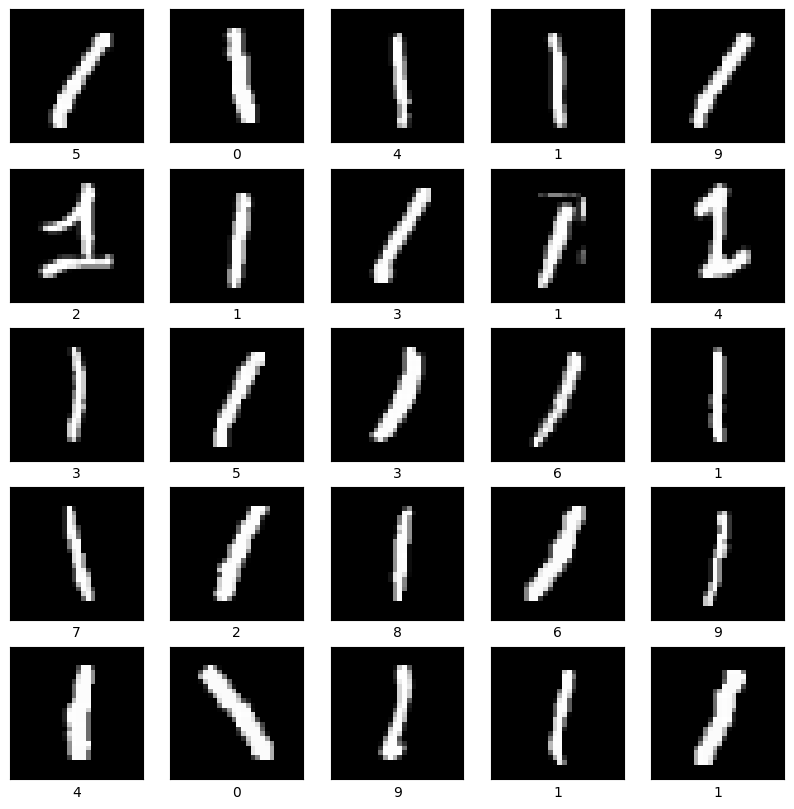

In [6]:
plt.figure(figsize=(10,10))

number_to_display = 1;

count = 0
for i in range(25):
  found = train_labels[count] == number_to_display
  while not found:
    count = count + 1
    found = train_labels[count] == number_to_display

  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.grid(False)
  plt.imshow(train_images[count], cmap='gray')
  # The CIFAR labels happen to be arrays,
  # which is why you need the extra index
  plt.xlabel(class_names[train_labels[i]])
  count = count+1
plt.show()

Some data processing to create the train_dataset:

In [7]:
train_images = train_images.reshape(train_images.shape[0], 28, 28, 1).astype('float32')
train_images = (train_images - 127.5) / 127.5  # Normalize the images to [-1, 1]

# Batch and shuffle the data
BUFFER_SIZE = 60000 # total number of images
BATCH_SIZE = 256 # number of images in each mini-batch
train_dataset = tf.data.Dataset.from_tensor_slices(train_images).shuffle(BUFFER_SIZE).batch(BATCH_SIZE)

## 5) Create Generator model

GANs are composed of two models, the generator and the discriminator.

We create a simple generator here:

In [8]:
generator = tf.keras.Sequential()
generator.add(layers.Dense(7*7*256, use_bias=False, input_shape=(100,)))
generator.add(layers.BatchNormalization())
generator.add(layers.LeakyReLU())
generator.add(layers.Reshape((7, 7, 256)))
generator.add(layers.Conv2DTranspose(128, (5, 5), strides=(1, 1), padding='same', use_bias=False))
generator.add(layers.BatchNormalization())
generator.add(layers.LeakyReLU())
generator.add(layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False))
generator.add(layers.BatchNormalization())
generator.add(layers.LeakyReLU())
generator.add(layers.Conv2DTranspose(1, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh'))



And we visualise the architecture of the generator:

In [9]:
generator.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 12544)             1254400   
                                                                 
 batch_normalization (Batch  (None, 12544)             50176     
 Normalization)                                                  
                                                                 
 leaky_re_lu (LeakyReLU)     (None, 12544)             0         
                                                                 
 reshape (Reshape)           (None, 7, 7, 256)         0         
                                                                 
 conv2d_transpose (Conv2DTr  (None, 7, 7, 128)         819200    
 anspose)                                                        
                                                                 
 batch_normalization_1 (Bat  (None, 7, 7, 128)         5

## 6) Generate image with the generator

The generator is not trained, but you can already use it to generate a single image.

First we generate random noise, which will be the input to the network:

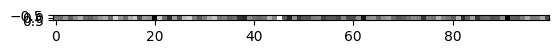

In [10]:
noise = tf.random.normal([1, 100]) # We need to feed some noise to the generator to generate a new image
plt.imshow(noise, cmap='gray') # we show the generated image.


We then use the generator to generate an image:

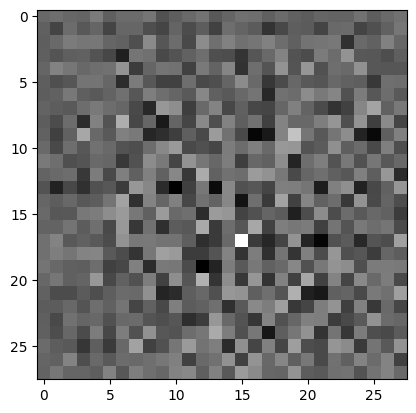

In [11]:
generated_image = generator(noise, training=False)
plt.imshow(generated_image[0, :, :, 0], cmap='gray') # we show the generated image.

The image is totally random because the generator has not been trained.

## 7) Create a Discriminator model

In [12]:
discriminator = tf.keras.Sequential()
discriminator.add(layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same', input_shape=[28, 28, 1]))
discriminator.add(layers.LeakyReLU())
discriminator.add(layers.Dropout(0.3))
discriminator.add(layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'))
discriminator.add(layers.LeakyReLU())
discriminator.add(layers.Dropout(0.3))
discriminator.add(layers.Flatten())
discriminator.add(layers.Dense(1))

We can already use the discriminator to predict if an image is real or fake.

- negative values are for fake images
- positive values are for real images

In [13]:

decision = discriminator(generated_image)
print (decision)

tf.Tensor([[-0.00495911]], shape=(1, 1), dtype=float32)


In [14]:
# This method returns a helper function to compute cross entropy loss
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

## 8) Define the loss functions for the discriminator and the generator, and the optimisers

We need to define our own loss functions since we have two networks that they are competing with each other.

In [15]:
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = real_loss + fake_loss
    return total_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

## 9) Train models together

Now we need the two networks together.
For each epoch, an image of generated numbers is displayed at the bottom.

You can see that after each epoch the network gets slightly better at generatoing images of numbers.

In [16]:
EPOCHS = 50
noise_dim = 100
num_examples_to_generate = 16 # defines the number of examples to generate in each training loop

# You will reuse this seed overtime (so it's easier)
# to visualize progress in the animated GIF)
seed = tf.random.normal([num_examples_to_generate, noise_dim])

In [17]:
# Notice the use of `tf.function`
# This annotation causes the function to be "compiled".
@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
      generated_images = generator(noise, training=True)

      real_output = discriminator(images, training=True)
      fake_output = discriminator(generated_images, training=True)

      gen_loss = generator_loss(fake_output)
      disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

In [18]:
def train(dataset, epochs):
  for epoch in range(epochs):
    start = time.time()

    for image_batch in dataset:
      train_step(image_batch)

    # Produce images for the GIF as you go
    display.clear_output(wait=True)
    generate_image(generator, seed)

    print ('Time for epoch {} is {} sec'.format(epoch + 1, time.time()-start))

  # Generate after the final epoch
  display.clear_output(wait=True)
  generate_image(generator, seed)

In [19]:
def generate_image(model, test_input):
  # Notice `training` is set to False.
  # This is so all layers run in inference mode (batchnorm).
  predictions = model(test_input, training=False)

  fig = plt.figure(figsize=(4, 4))

  for i in range(predictions.shape[0]):
      plt.subplot(4, 4, i+1)
      plt.imshow(predictions[i, :, :, 0] * 127.5 + 127.5, cmap='gray')
      plt.axis('off')
  plt.show()

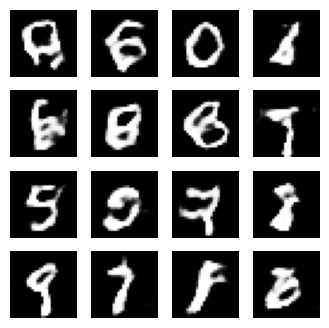

In [20]:
train(train_dataset, EPOCHS)

## 10) Generate a new image

After training, you can generate new images of numbers by giving as input random noise.

The longer you train, the better the quality of the generated images.

You can run the following code as many times as you want; it will generate a new image every time.

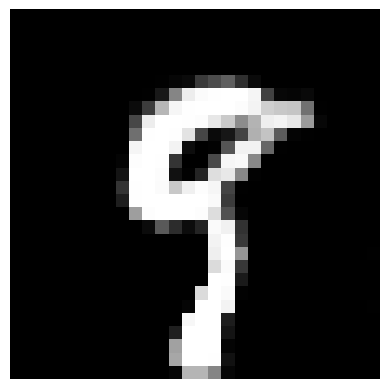

In [25]:
seed = tf.random.normal([1, noise_dim])
predictions = generator(seed, training=False)

plt.imshow(predictions[0, :, :, 0] * 127.5 + 127.5, cmap='gray')
plt.axis('off')
plt.show()